# Dental Lesion Detection — Dataset Exploration

Review of the original X-rays and their XML annotations.

Augmented images are excluded because some contain annotations that do not correspond to the lesions. This notebook does not modify the dataset.

In [1]:
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

#Main dataset path
DATASET_DIR = Path("../dataset")

#Find original X-rays and XML annotation files
original_images = sorted(
    f for f in DATASET_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() == ".jpg"
    and f.parent.name == "Original JPG Images"
)

xml_files = sorted(
    f for f in DATASET_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() == ".xml"
)

#Match annotations to images using filenames
xml_by_name = {f.stem: f for f in xml_files}

print("Original images:", len(original_images))
print("XML files found:", len(xml_files))

Original images: 3875
XML files found: 17004


In [3]:
#Check image and annotation files
valid_pairs = []
missing_xml = []
dimension_errors = []
invalid_images = []
class_counts = Counter()
total_boxes = 0

for img_path in original_images:
    xml_path = xml_by_name.get(img_path.stem)

    if xml_path is None:
        missing_xml.append(img_path.name)
        continue

    root = ET.parse(xml_path).getroot()
    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    with Image.open(img_path) as img:
        if img.size != (width, height):
            dimension_errors.append(img_path.name)
            continue

    boxes = []
    image_ok = True

    for obj in root.findall("object"):
        box = obj.find("bndbox")
        if box is None:
            image_ok = False
            break

        try:
            x1 = int(box.findtext("xmin"))
            y1 = int(box.findtext("ymin"))
            x2 = int(box.findtext("xmax"))
            y2 = int(box.findtext("ymax"))
        except (TypeError, ValueError):
            image_ok = False
            break

        if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
            image_ok = False
            break

        boxes.append((obj.findtext("name"), x1, y1, x2, y2))

    if image_ok and boxes:
        valid_pairs.append((img_path, xml_path, boxes))
        total_boxes += len(boxes)
        class_counts.update(label for label, *_ in boxes)
    else:
        invalid_images.append(img_path.name)

print("Valid original images:", len(valid_pairs))
print("Missing XML:", len(missing_xml))
print("Dimension errors:", len(dimension_errors))
print("Images with invalid boxes:", len(invalid_images))
print("Valid annotations:", total_boxes)
print("Class distribution:", dict(sorted(class_counts.items())))

Valid original images: 3875
Missing XML: 0
Dimension errors: 0
Images with invalid boxes: 0
Valid annotations: 6631
Class distribution: {'3': 4198, '4': 1736, '5': 697}


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


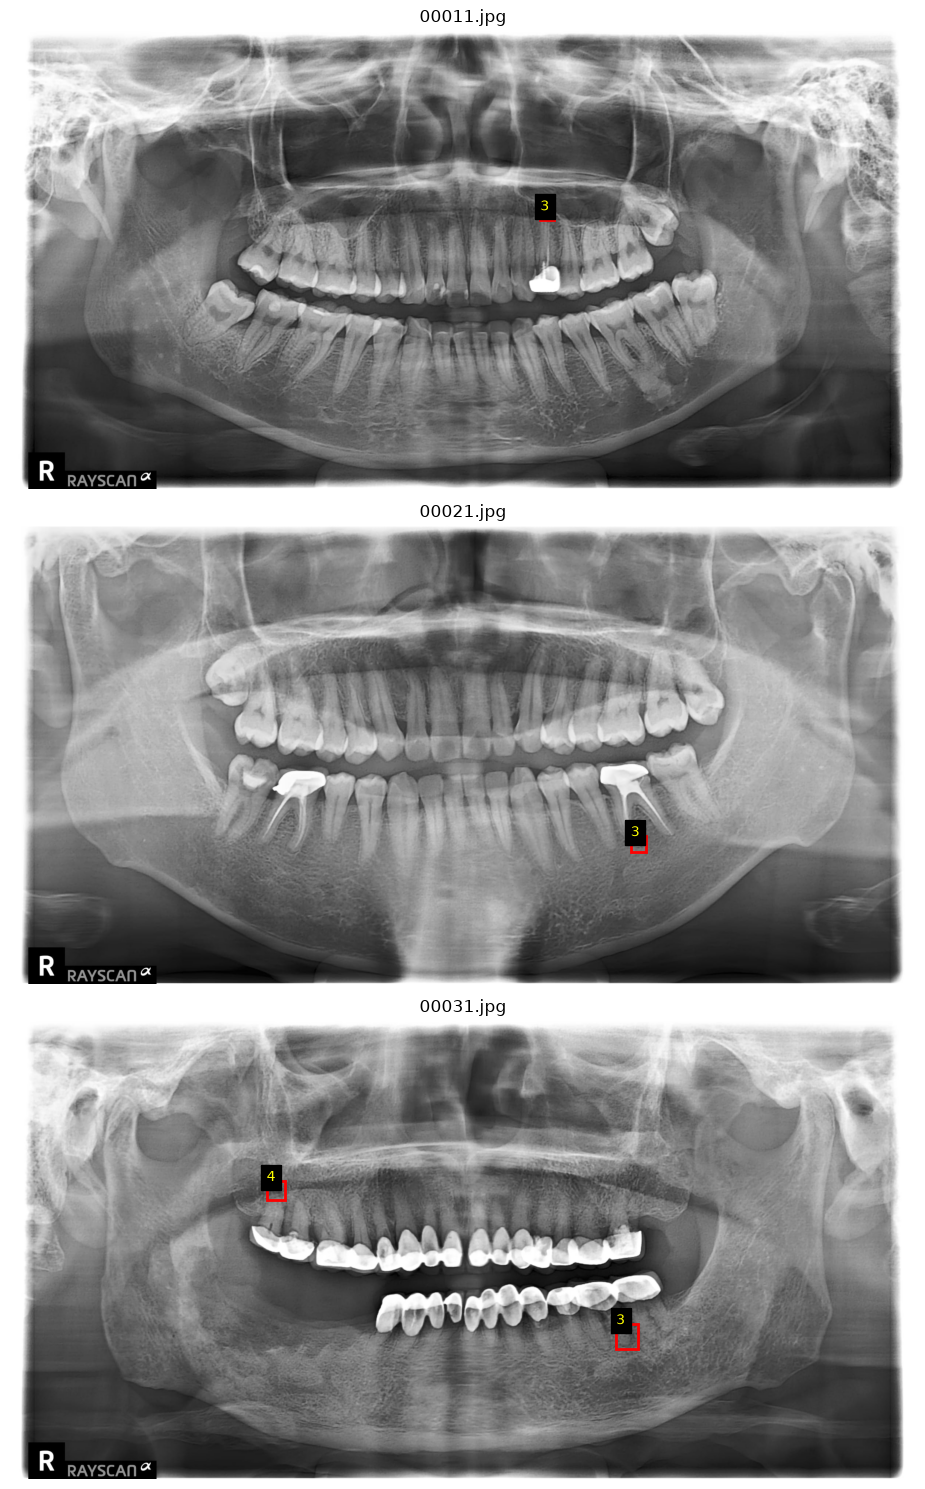

In [4]:
#Show X-rays with their bounding boxes
examples = valid_pairs[:3]

fig, axes = plt.subplots(len(examples), 1, figsize=(12, 5 * len(examples)))
if len(examples) == 1:
    axes = [axes]

for ax, (img_path, xml_path, boxes) in zip(axes, examples):
    with Image.open(img_path) as img:
        ax.imshow(img.convert("RGB"))

    for label, x1, y1, x2, y2 in boxes:
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            edgecolor="red", facecolor="none", linewidth=2
        )
        ax.add_patch(rect)
        ax.text(x1, y1, label, color="yellow",
                fontsize=10, backgroundcolor="black")

    ax.set_title(img_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()